In [4]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

In [5]:
df = pd.read_csv(r"C:\Users\bolle\Downloads\archive (8)\Loan_default.csv")
df

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


In [6]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [8]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner',
       'Default'],
      dtype='object')

In [9]:
df.describe().sum()

Age               2.556225e+05
Income            7.893188e+05
LoanAmount        1.091463e+06
CreditScore       2.589522e+05
MonthsEmployed    2.557402e+05
NumCreditLines    2.553626e+05
InterestRate      2.554346e+05
LoanTerm          2.555800e+05
DTIRatio          2.553502e+05
Default           2.553484e+05
dtype: float64

In [13]:
df.shape

(255347, 18)

In [16]:
# Check missing values

print(df.isnull().sum())

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64


In [17]:
# Check duplicate rows

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [18]:
# Check duplicate rows

print("Duplicate columns:", df.duplicated().sum())

Duplicate columns: 0


In [19]:
# Count default and non-default customers

print(df["Default"].value_counts())

Default
0    225694
1     29653
Name: count, dtype: int64


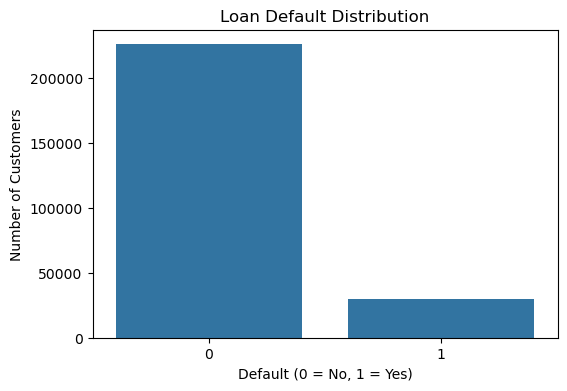

In [20]:
#  EDA


# default prediction visualization

plt.figure(figsize=(6,4))

sns.countplot(x="Default", data=df)

plt.title("Loan Default Distribution")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

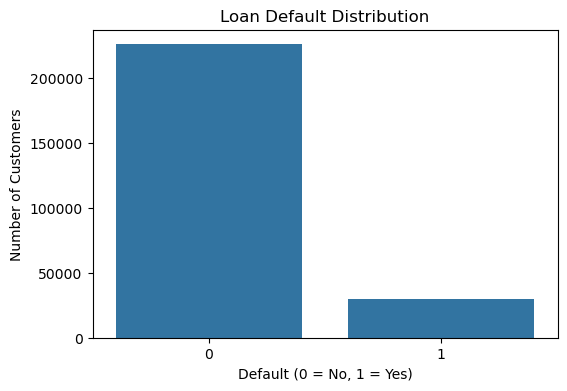

In [57]:
#Credit Score vs Default

plt.figure(figsize=(6,4))

sns.countplot(x="Default", data=df)

plt.title("Loan Default Distribution")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()

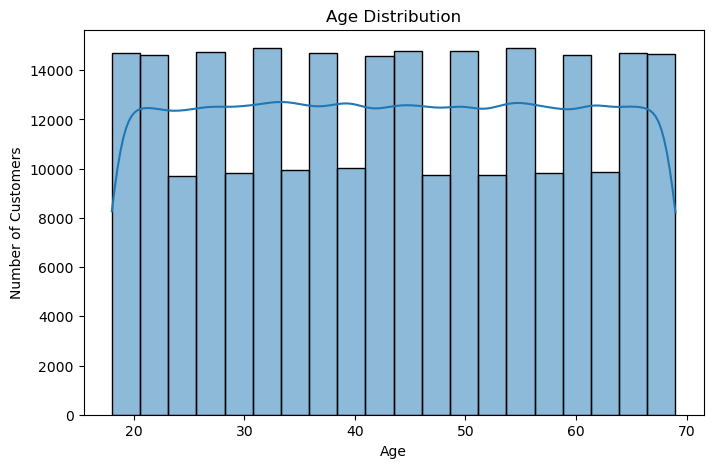

In [58]:
#  Age Distribution
plt.figure(figsize=(8,5))

sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

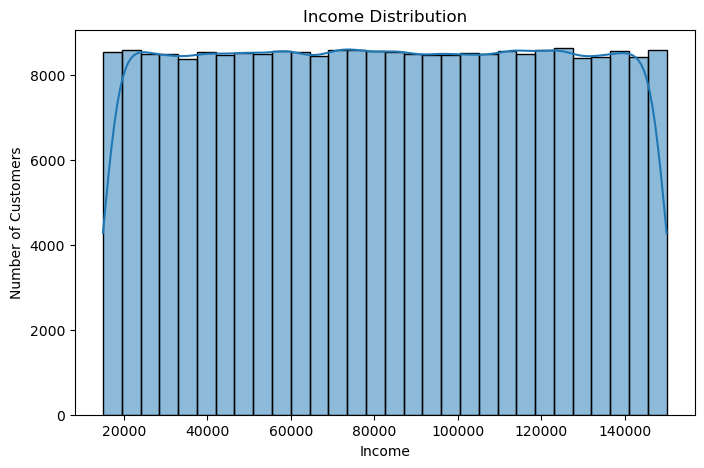

In [59]:
# income Distribution
plt.figure(figsize=(8,5))

sns.histplot(df["Income"], bins=30, kde=True)

plt.title("Income Distribution")
plt.xlabel("Income")
plt.ylabel("Number of Customers")

plt.show()

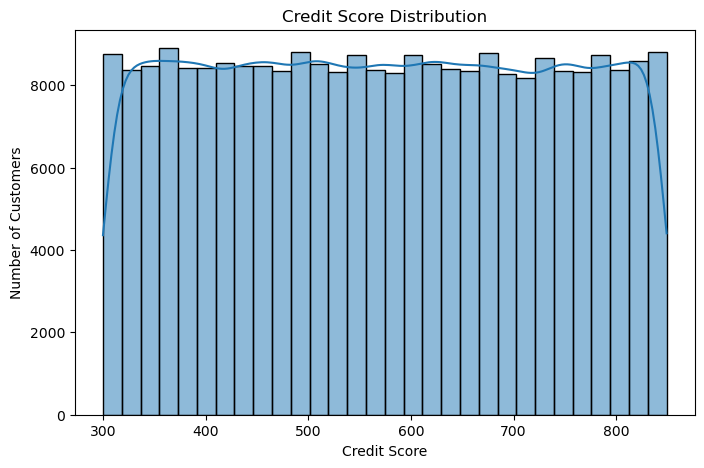

In [60]:
#  Credit Score Distribution
plt.figure(figsize=(8,5))

sns.histplot(df["CreditScore"], bins=30, kde=True)

plt.title("Credit Score Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")

plt.show()

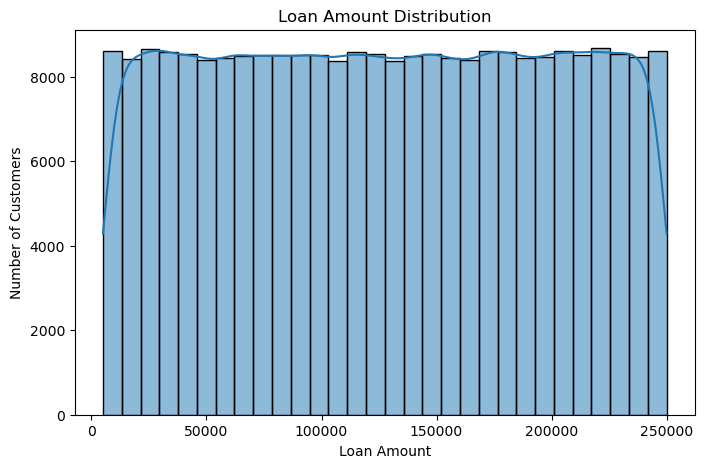

In [61]:
#  Loan Amount Distribution
plt.figure(figsize=(8,5))

sns.histplot(df["LoanAmount"], bins=30, kde=True)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Customers")

plt.show()

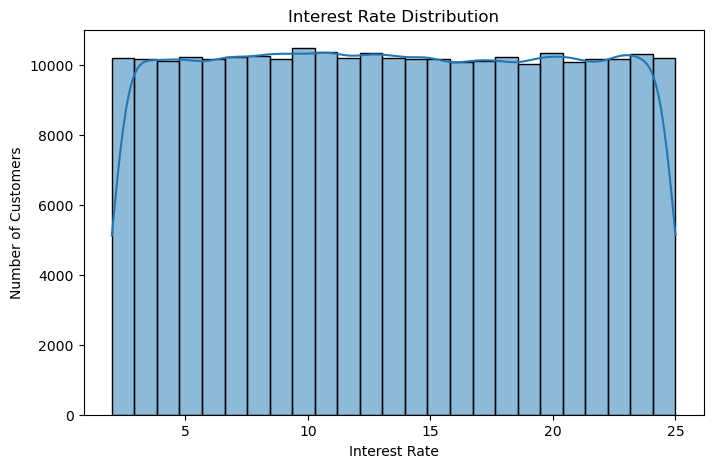

In [62]:
#  Interest Rate Distribution

plt.figure(figsize=(8,5))

sns.histplot(df["InterestRate"], bins=25, kde=True)

plt.title("Interest Rate Distribution")
plt.xlabel("Interest Rate")
plt.ylabel("Number of Customers")

plt.show()

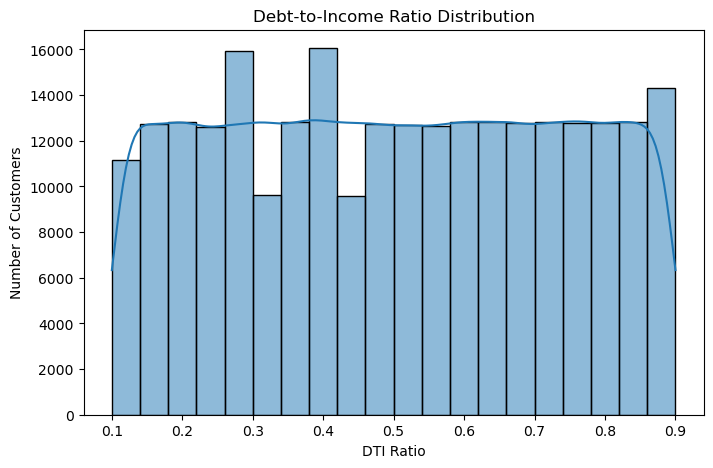

In [63]:
# DTI Ratio Distribution


plt.figure(figsize=(8,5))

sns.histplot(df["DTIRatio"], bins=20, kde=True)

plt.title("Debt-to-Income Ratio Distribution")
plt.xlabel("DTI Ratio")
plt.ylabel("Number of Customers")

plt.show()

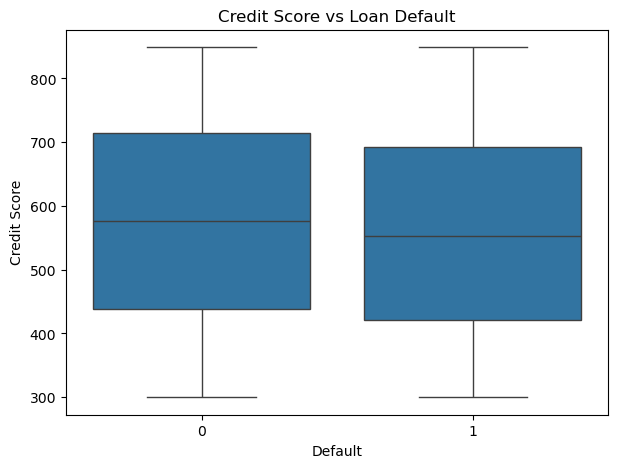

In [64]:
#  Credit Score vs Default


plt.figure(figsize=(7,5))

sns.boxplot(
    x="Default",
    y="CreditScore",
    data=df
)

plt.title("Credit Score vs Loan Default")
plt.xlabel("Default")
plt.ylabel("Credit Score")

plt.show()

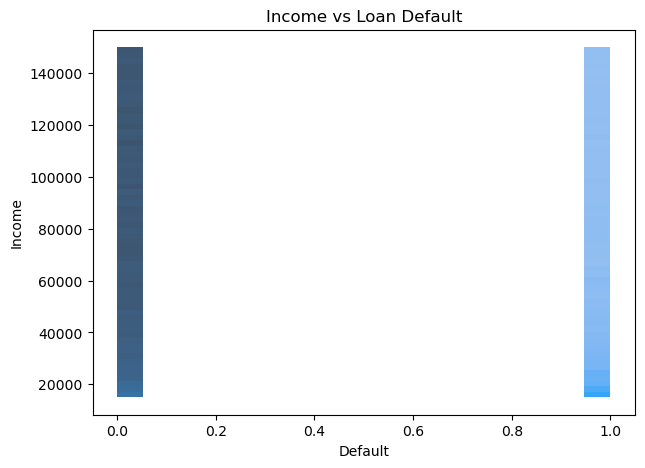

In [66]:
#  Income vs Default


plt.figure(figsize=(7,5))

sns.histplot(
    x="Default",
    y="Income",
    data=df
)

plt.title("Income vs Loan Default")
plt.xlabel("Default")
plt.ylabel("Income")

plt.show()

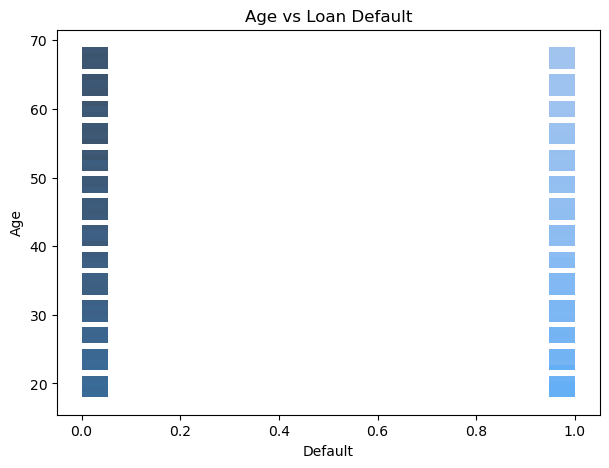

In [67]:
# Age vs Default


plt.figure(figsize=(7,5))

sns.histplot(
    x="Default",
    y="Age",
    data=df
)

plt.title("Age vs Loan Default")
plt.xlabel("Default")
plt.ylabel("Age")

plt.show()

In [28]:
# DATA PREPROCESSING

#Prepare the Data

#We don't need LoanID for prediction because it is just an identifier.

# Remove LoanID

df = df.drop("LoanID", axis=1)

# Display remaining columns

df.head()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [31]:
#Separate Features and Target

#X = input features

#y = target/output

# Features
X = df.drop("Default", axis=1)

# Target
y = df["Default"]

print("Features:")
print(X.columns)

print("\nTarget:")
print(y.name)

Features:
Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education',
       'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents',
       'LoanPurpose', 'HasCoSigner'],
      dtype='object')

Target:
Default


In [32]:
#Identify Numerical and Categorical Columns
# Numerical columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Categorical columns

categorical_columns = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

Categorical Columns:
['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


In [ ]:
# FEATURE ENGINEERING

In [68]:
#  Create Credit Risk Category

def credit_risk(score):
    if score < 580:
        return "Poor"
    elif score < 670:
        return "Fair"
    elif score < 740:
        return "Good"
    else:
        return "Excellent"

df["CreditRisk"] = df["CreditScore"].apply(credit_risk)

In [71]:
df[["CreditScore", "CreditRisk"]].head(10)

,CreditScore,CreditRisk
0,520,Poor
1,458,Poor
2,451,Poor
3,743,Excellent
4,633,Fair
5,720,Good
6,429,Poor
7,531,Poor
8,827,Excellent
9,480,Poor


In [72]:
#  Create High Interest Rate Feature

average_interest = df["InterestRate"].mean()

df["HighInterestRate"] = (
    df["InterestRate"] > average_interest
).astype(int)

In [74]:
df[["InterestRate", "HighInterestRate"]].head()

,InterestRate,HighInterestRate
0,15.23,1
1,4.81,0
2,21.17,1
3,7.07,0
4,6.51,0


In [75]:
#Create High DTI Feature

average_dti = df["DTIRatio"].mean()

df["HighDTI"] = (
    df["DTIRatio"] > average_dti
).astype(int)

In [76]:
df[["DTIRatio", "HighDTI"]].head()

,DTIRatio,HighDTI
0,0.44,0
1,0.68,1
2,0.31,0
3,0.23,0
4,0.73,1


In [78]:
# ============================================
# FEATURE ENGINEERING
# ============================================

import pandas as pd

# Load dataset
df = pd.read_csv(r"C:\Users\bolle\Downloads\archive (8)\Loan_default.csv")
df

# Remove LoanID
df = df.drop("LoanID", axis=1)

# 1. Loan amount compared with income
df["LoanToIncomeRatio"] = df["LoanAmount"] / (df["Income"] + 1)

# 2. Income compared with loan amount
df["IncomePerLoan"] = df["Income"] / (df["LoanAmount"] + 1)

# 3. Credit risk category
def credit_risk(score):
    if score < 580:
        return "Poor"
    elif score < 670:
        return "Fair"
    elif score < 740:
        return "Good"
    else:
        return "Excellent"

df["CreditRisk"] = df["CreditScore"].apply(credit_risk)

# 4. Employment experience compared with age
df["EmploymentAgeRatio"] = (
    df["MonthsEmployed"] / ((df["Age"] * 12) + 1)
)

# 5. High interest rate
average_interest = df["InterestRate"].mean()

df["HighInterestRate"] = (
    df["InterestRate"] > average_interest
).astype(int)

# 6. High DTI
average_dti = df["DTIRatio"].mean()

df["HighDTI"] = (
    df["DTIRatio"] > average_dti
).astype(int)

# Display dataset
print("Dataset shape:", df.shape)

print("\nNew features:")
print([
    "LoanToIncomeRatio",
    "IncomePerLoan",
    "CreditRisk",
    "EmploymentAgeRatio",
    "HighInterestRate",
    "HighDTI"
])

df.head()

Dataset shape: (255347, 23)

New features:
['LoanToIncomeRatio', 'IncomePerLoan', 'CreditRisk', 'EmploymentAgeRatio', 'HighInterestRate', 'HighDTI']


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,...,HasDependents,LoanPurpose,HasCoSigner,Default,LoanToIncomeRatio,IncomePerLoan,CreditRisk,EmploymentAgeRatio,HighInterestRate,HighDTI
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,...,Yes,Other,Yes,0,0.588255,1.699889,Poor,0.118871,1,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,...,No,Other,Yes,0,2.467432,0.405268,Poor,0.018094,0,1
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,...,Yes,Auto,No,1,1.534135,0.651820,Poor,0.047016,1,0
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,...,No,Business,No,0,1.412594,0.707879,Excellent,0.000000,0,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,...,Yes,Auto,No,0,0.447157,2.235996,Fair,0.011096,0,1


In [ ]:
#  ENDODING +  SCALLING

In [79]:
#  Separate X and y
# Separate features and target

X = df.drop("Default", axis=1)
y = df["Default"]

In [83]:
#  Identify numerical and categorical columns
# Numerical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio',
       'LoanToIncomeRatio', 'IncomePerLoan', 'EmploymentAgeRatio',
       'HighInterestRate', 'HighDTI'],
      dtype='object')

Categorical columns:
Index(['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage',
       'HasDependents', 'LoanPurpose', 'HasCoSigner', 'CreditRisk'],
      dtype='object')


In [84]:
#  Split the data


from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (204277, 22)
Testing data: (51070, 22)


In [86]:
#Encoding and Scaling 


from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ]
)


In [87]:
preprocessor

ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                 Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio',
       'LoanToIncomeRatio', 'IncomePerLoan', 'EmploymentAgeRatio',
       'HighInterestRate', 'HighDTI'],
      dtype='object')),
                                ('categorical',
                                 OneHotEncoder(handle_unknown='ignore'),
                                 Index(['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage',
       'HasDependents', 'LoanPurpose', 'HasCoSigner', 'CreditRisk'],
      dtype='object'))])

In [34]:
# Train-Test Split

# We'll use:

# 80% → Training

# 20% → Testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (204277, 16)
Testing data: (51070, 16)


In [39]:
#  Model 1 — Logistic Regression

#  Logistic Regression is a good and easy-to-understand classification model.

# Logistic Regression Pipeline

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000
            )
        )
    ]
)

# Train model

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [40]:
# Make Predictions — Logistic Regression
# Predictions

y_pred_lr = logistic_model.predict(X_test)

# Prediction probabilities

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

In [41]:
#  Evaluate Logistic Regression
print("Logistic Regression Results")
print("--------------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_lr)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_lr)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_lr)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_lr)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_lr)
)

Logistic Regression Results
--------------------------------
Accuracy: 0.6763853534364598
Precision: 0.21950444726810672
Recall: 0.6990389479008599
F1 Score: 0.3340988758612353
ROC-AUC: 0.753178399553392


In [42]:
#  Classification Report
print(
    classification_report(
        y_test,
        y_pred_lr
    )
)

              precision    recall  f1-score   support

           0       0.94      0.67      0.79     45139
           1       0.22      0.70      0.33      5931

    accuracy                           0.68     51070
   macro avg       0.58      0.69      0.56     51070
weighted avg       0.86      0.68      0.73     51070



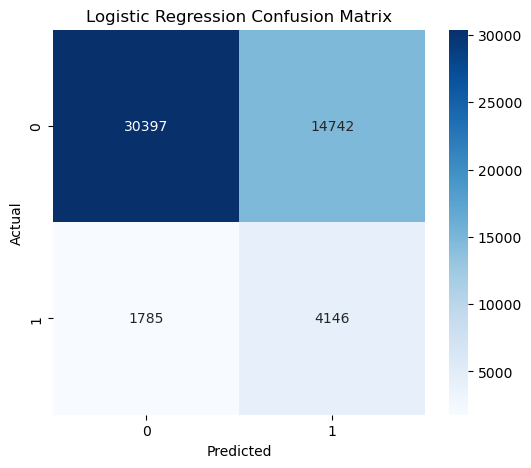

In [43]:
#  Confusion Matrix — Logistic Regression
cm = confusion_matrix(
    y_test,
    y_pred_lr
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [44]:
# Model 2 — Random Forest

# Now we'll use Random Forest.

# Random Forest Pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

# Train model

random_forest_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [45]:
# Make Predictions — Random Forest
# Predictions

y_pred_rf = random_forest_model.predict(X_test)

# Prediction probabilities

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [46]:
#  Evaluate Random Forest
print("Random Forest Results")
print("--------------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_rf)
)

print(
    "Precision:",
    precision_score(y_test, y_pred_rf)
)

print(
    "Recall:",
    recall_score(y_test, y_pred_rf)
)

print(
    "F1 Score:",
    f1_score(y_test, y_pred_rf)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_prob_rf)
)

Random Forest Results
--------------------------------
Accuracy: 0.8847464264734678
Precision: 0.6956521739130435
Recall: 0.013488450514247175
F1 Score: 0.026463777704267284
ROC-AUC: 0.7378782929406512


In [47]:
#  Classification Report — Random Forest
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

              precision    recall  f1-score   support

           0       0.89      1.00      0.94     45139
           1       0.70      0.01      0.03      5931

    accuracy                           0.88     51070
   macro avg       0.79      0.51      0.48     51070
weighted avg       0.86      0.88      0.83     51070



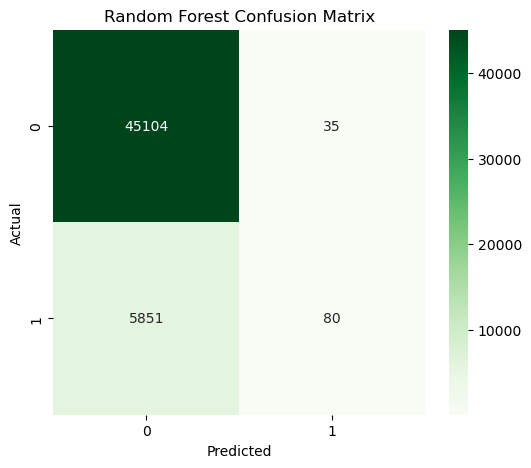

In [48]:
#  Confusion Matrix — Random Forest
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens"
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [49]:
#  MODEL EVALUATION

#   Compare Both Models

#  This is an important part of your project.

# Compare models

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.676385,0.219504,0.699039,0.334099,0.753178
1,Random Forest,0.884746,0.695652,0.013488,0.026464,0.737878


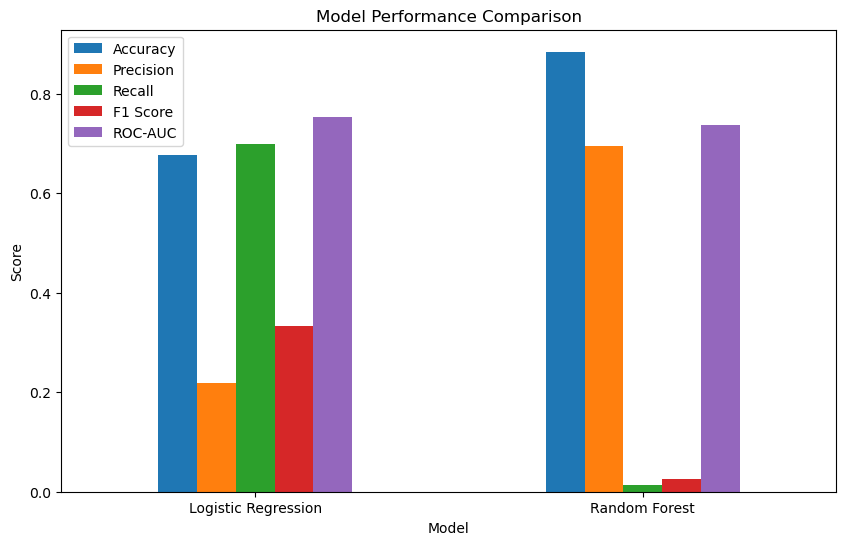

In [50]:
#  Display comparison as a graph
results.set_index("Model").plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Model Performance Comparison")

plt.ylabel("Score")

plt.xticks(rotation=0)

plt.legend()

plt.show()

In [54]:
#Predict a New Loan

#  Now comes the interesting part — using the model to predict whether a new customer may default.

#  For example:

# Take one customer from test data

sample_customer = X_test.iloc[[0]]

# Predict

prediction = random_forest_model.predict(
    sample_customer
)

probability = random_forest_model.predict_proba(
    sample_customer
)[0][1]

print("Prediction:", prediction[0])

print(
    "Default Probability:",
    round(probability * 100, 2),
    "%"
)


Prediction: 0
Default Probability: 3.0 %


In [56]:
#  Display Final Result


if prediction[0] == 1:
    print(" Prediction: Customer may default on the loan.")
else:
    print(" Prediction: Customer is unlikely to default.")


 Prediction: Customer is unlikely to default.
